# K-Nearest Neighbors (KNN)

**K-Nearest Neighbors (KNN)** is one of the most intuitive and foundational supervised machine learning algorithms.

### Key Characteristics:
- **Instance-Based (Memory-Based):** It does not learn an explicit set of parameters (like weights $\theta$ in Linear or Logistic Regression). Instead, it stores the entire training dataset.
- **Lazy Learner:** Training is $O(1)$ because the model simply retains the data. All computation occurs during inference / prediction time.
- **Non-Parametric:** It makes no assumptions regarding the underlying probability distribution of the data, allowing it to adapt to complex, non-linear decision boundaries.

The guiding intuition is:
> **"Tell me who your neighbors are, and I will tell you who you are."**

## Distance Metrics

To identify the "nearest" neighbors to a query point $\mathbf{x}$, we need a metric to compute distances in the feature space. Given two $d$-dimensional feature vectors $\mathbf{x}^{(a)}$ and $\mathbf{x}^{(b)}$:

### 1. Euclidean Distance ($L_2$ norm)
The straight-line geometric distance:
$$d_2(\mathbf{x}^{(a)}, \mathbf{x}^{(b)}) = \sqrt{\sum_{j=1}^{d} (x_j^{(a)} - x_j^{(b)})^2} = \|\mathbf{x}^{(a)} - \mathbf{x}^{(b)}\|_2$$

### 2. Manhattan Distance ($L_1$ norm / Taxicab distance)
The distance moving only along grid axes (sum of absolute differences):
$$d_1(\mathbf{x}^{(a)}, \mathbf{x}^{(b)}) = \sum_{j=1}^{d} |x_j^{(a)} - x_j^{(b)}| = \|\mathbf{x}^{(a)} - \mathbf{x}^{(b)}\|_1$$

### 3. Minkowski Distance ($L_p$ norm)
The generalized distance metric that includes Manhattan ($p=1$) and Euclidean ($p=2$) as special cases:
$$d_p(\mathbf{x}^{(a)}, \mathbf{x}^{(b)}) = \left( \sum_{j=1}^{d} |x_j^{(a)} - x_j^{(b)}|^p \right)^{\frac{1}{p}} = \|\mathbf{x}^{(a)} - \mathbf{x}^{(b)}\|_p$$

In [34]:
import numpy as np
import matplotlib.pyplot as plt

def euclidean_distance(x1, x2):
    # x1, x2 (ndarray): Two feature vectors of shape (d,)
    return np.sqrt(np.sum((x1 - x2) ** 2))

def manhattan_distance(x1, x2):
    # x1, x2 (ndarray): Two feature vectors of shape (d,)
    return np.sum(np.abs(x1 - x2))

def minkowski_distance(x1, x2, p=3):
    # x1, x2 (ndarray): Two feature vectors of shape (d,)
    # p (int/float): The norm order
    return np.sum(np.abs(x1 - x2) ** p) ** (1 / p)

# Demonstration of distance metrics
point_a = np.array([1.0, 2.0])
point_b = np.array([4.0, 6.0])

print(f"Point A: {point_a}, Point B: {point_b}")
print(f"Euclidean Distance (L2): {euclidean_distance(point_a, point_b):.4f}")
print(f"Manhattan Distance (L1): {manhattan_distance(point_a, point_b):.4f}")
print(f"Minkowski Distance (p=3): {minkowski_distance(point_a, point_b, p=3):.4f}")

Point A: [1. 2.], Point B: [4. 6.]
Euclidean Distance (L2): 5.0000
Manhattan Distance (L1): 7.0000
Minkowski Distance (p=3): 4.4979


## Loading Dataset

To visualize how KNN partitions the feature space across multiple classes, we generate synthetic 2D data with three distinct clusters arranged in a circle.

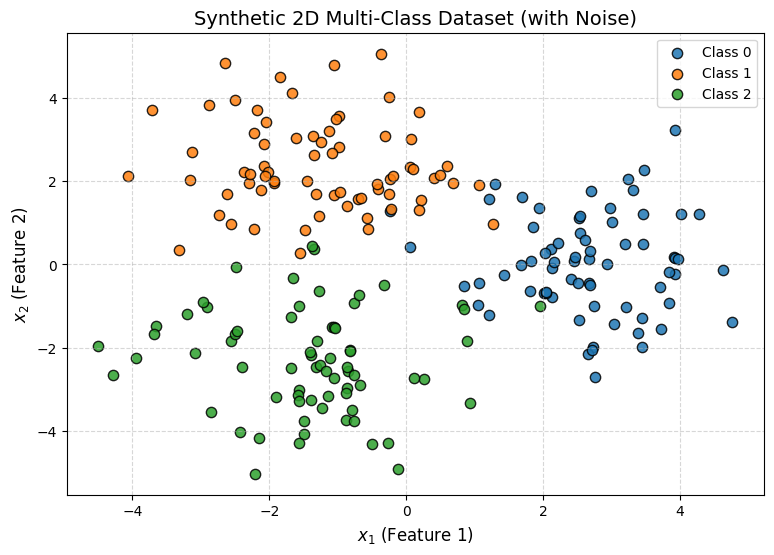

In [35]:
def generate_synthetic_data(n_classes=3, points_per_class=70, cluster_std=1.1, noise=0.5, random_state=42):
    # n_classes (int): Number of target classes
    # points_per_class (int): Samples per class
    # cluster_std (float): Spread / standard deviation of each cluster
    # noise (float): Standard deviation of Gaussian noise added to features
    np.random.seed(random_state)
    X_list, y_list, centers = [], [], []
    radius = 2.8
    
    for c in range(n_classes):
        angle = 2 * np.pi * c / n_classes
        center = [radius * np.cos(angle), radius * np.sin(angle)]
        centers.append(center)
        cov = [[cluster_std ** 2, 0], [0, cluster_std ** 2]]
        class_samples = np.random.multivariate_normal(center, cov, points_per_class)
        
        # Add random Gaussian noise to create natural boundary overlap
        class_samples += np.random.normal(0, noise, size=class_samples.shape)
        
        X_list.append(class_samples)
        y_list.extend([c] * points_per_class)
        
    X = np.vstack(X_list)
    y = np.array(y_list)
    return X, y, centers

# Generate 3 classes of 2D data with realistic noise
n_classes = 3
X, y, class_centers = generate_synthetic_data(n_classes=n_classes, points_per_class=70, cluster_std=1.1, noise=0.5)

# Visualize the dataset
plt.figure(figsize=(9, 6))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
for c in range(n_classes):
    plt.scatter(X[y == c, 0], X[y == c, 1], color=colors[c], label=f'Class {c}', edgecolors='k', s=55, alpha=0.85)

plt.title('Synthetic 2D Multi-Class Dataset (with Noise)', fontsize=14)
plt.xlabel('$x_1$ (Feature 1)', fontsize=12)
plt.ylabel('$x_2$ (Feature 2)', fontsize=12)
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Train / Test Split

We partition our dataset into **training (80%)** and **testing (20%)** sets. Using `stratify=y` guarantees that the class proportions remain identical in both sets.

In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Total samples:    {X.shape[0]}")
print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples:  {X_test.shape[0]}")

Total samples:    210
Training samples: 168
Testing samples:  42


## KNN Classifier Algorithm

Given a training set $\mathcal{D} = \{(\mathbf{x}_i, y_i)\}_{i=1}^{m}$ and a new query point $\mathbf{x}_{\text{query}}$:

1. **Calculate Distances:** Compute distance $d(\mathbf{x}_{\text{query}}, \mathbf{x}_i)$ for all $i \in \{1, \dots, m\}$.
2. **Select $K$ Nearest Neighbors:** Sort distances and select the set $\mathcal{N}_K(\mathbf{x}_{\text{query}})$ of indices corresponding to the $K$ smallest distances.
3. **Voting / Label Aggregation:**
   - **Simple Majority Vote (Uniform):**
     $$\hat{y} = \operatorname{argmax}_{c} \sum_{i \in \mathcal{N}_K(\mathbf{x}_{\text{query}})} \mathbb{I}(y_i = c)$$
   - **Distance-Weighted Vote:**
     $$w_i = \frac{1}{d(\mathbf{x}_{\text{query}}, \mathbf{x}_i) + \epsilon}, \quad \hat{y} = \operatorname{argmax}_{c} \sum_{i \in \mathcal{N}_K(\mathbf{x}_{\text{query}})} w_i \cdot \mathbb{I}(y_i = c)$$

In [37]:
class KNNClassifier:
    def __init__(self, k=3, distance_func=euclidean_distance, weights='uniform'):
        # k (int): Number of nearest neighbors
        # distance_func (callable): Distance metric function
        # weights (str): 'uniform' (majority vote) or 'distance' (inverse distance weighting)
        self.k = k
        self.distance_func = distance_func
        self.weights = weights
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        # In KNN, training simply memorizes the training data
        self.X_train = np.array(X)
        self.y_train = np.array(y)

    def _predict_single(self, x_query):
        # Step 1: Compute distances from query to all training points
        distances = np.array([self.distance_func(x_query, x_t) for x_t in self.X_train])
        
        # Step 2: Get indices of the k smallest distances
        k_indices = np.argsort(distances)[:self.k]
        k_labels = self.y_train[k_indices]
        
        # Step 3: Vote among neighbors
        if self.weights == 'uniform':
            counts = np.bincount(k_labels.astype(int))
            return np.argmax(counts)
        elif self.weights == 'distance':
            k_distances = distances[k_indices]
            weights = 1.0 / (k_distances + 1e-6)
            unique_classes = np.unique(self.y_train)
            scores = {c: 0.0 for c in unique_classes}
            for label, w in zip(k_labels, weights):
                scores[label] += w
            return max(scores, key=scores.get)
        else:
            raise ValueError(f"Unknown weights mode: {self.weights}")

    def predict(self, X):
        # X (ndarray): Matrix of query instances of shape (m_query, d)
        X = np.array(X)
        return np.array([self._predict_single(x) for x in X])

## Choose Hyperparameters and Run KNN

Let's initialize our classifier with $K=5$ and Euclidean distance, fit it to the training data, and evaluate its accuracy and confusion matrix on the test set.

KNN Test Accuracy with k=5: 88.10%


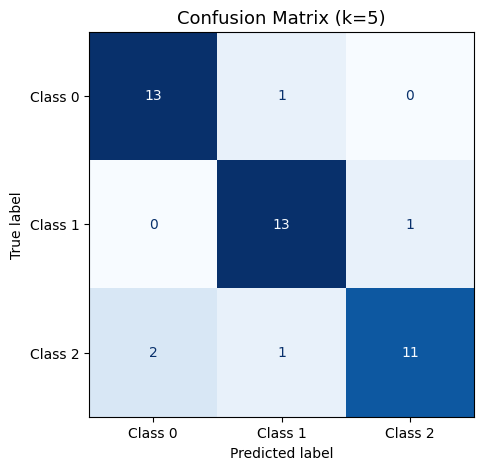

In [38]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Setup hyperparameters
k = 5
knn = KNNClassifier(k=k, distance_func=euclidean_distance, weights='uniform')

# Fit model (memorizes training set)
knn.fit(X_train, y_train)

# Predict on test set
y_pred = knn.predict(X_test)

# Compute accuracy
test_acc = accuracy_score(y_test, y_pred)
print(f"KNN Test Accuracy with k={k}: {test_acc * 100:.2f}%")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[f'Class {i}' for i in range(n_classes)])
disp.plot(cmap='Blues', ax=ax, colorbar=False)
plt.title(f'Confusion Matrix (k={k})', fontsize=13)
plt.grid(False)
plt.show()

## Plot Decision Boundaries

KNN creates decision regions by classifying points across the 2D feature space. We visualize this using a fine meshgrid.

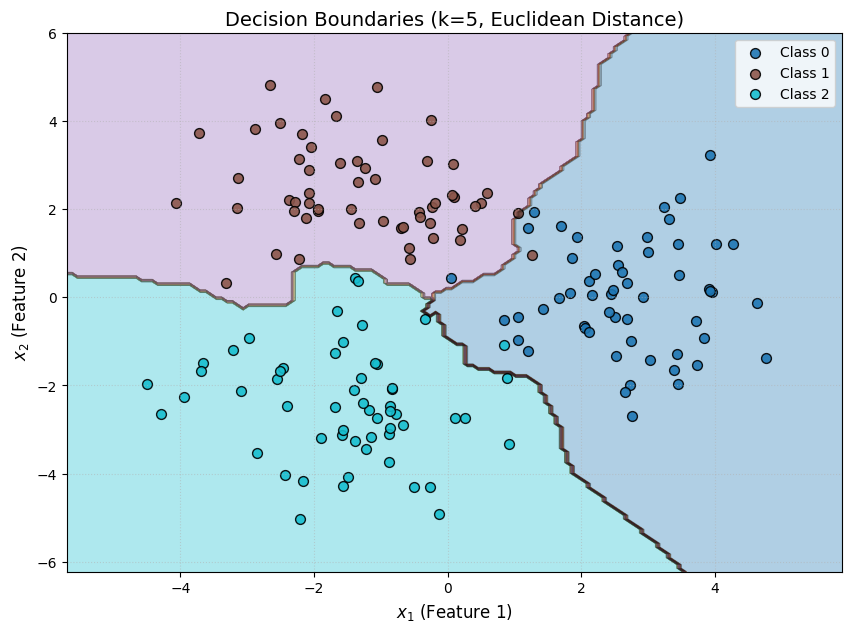

In [39]:
def plot_decision_boundaries(classifier, X, y, title='KNN Decision Boundaries'):
    # Generate fine grid
    h = 0.08
    x_min, x_max = X[:, 0].min() - 1.2, X[:, 0].max() + 1.2
    y_min, y_max = X[:, 1].min() - 1.2, X[:, 1].max() + 1.2
    
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    Z = classifier.predict(grid_points)
    Z = Z.reshape(xx.shape)
    
    plt.figure(figsize=(10, 7))
    n_classes = len(np.unique(y))
    colors = plt.cm.tab10(np.linspace(0, 1, n_classes))
    
    plt.contourf(xx, yy, Z, alpha=0.35, cmap='tab10')
    plt.contour(xx, yy, Z, colors='k', linewidths=0.7, alpha=0.4)
    
    for c in np.unique(y):
        plt.scatter(X[y == c, 0], X[y == c, 1],
                    color=colors[c], label=f'Class {c}',
                    edgecolors='k', s=50, alpha=0.9)
        
    plt.title(title, fontsize=14)
    plt.xlabel('$x_1$ (Feature 1)', fontsize=12)
    plt.ylabel('$x_2$ (Feature 2)', fontsize=12)
    plt.legend(frameon=True, loc='upper right')
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.show()

# Plot decision boundaries for k=5
plot_decision_boundaries(knn, X_train, y_train, title=f'Decision Boundaries (k={k}, Euclidean Distance)')

## Hyperparameter Analysis: The Effect of $K$ (Bias-Variance Tradeoff)

The number of neighbors $K$ acts as the model complexity regularizer:

- **Small $K$ (e.g., $K=1$):**
  - **Low Bias, High Variance (Overfitting):** Decision boundaries are highly complex, island-like, and sensitive to outliers or noise.
  - Training accuracy is $100\%$, but generalization error can be high.
- **Large $K$ (e.g., $K=25$):**
  - **High Bias, Low Variance (Underfitting):** Decision boundaries become overly smooth and simple, ignoring fine local structures.
  - Votes can be completely dominated by the globally prevalent class.

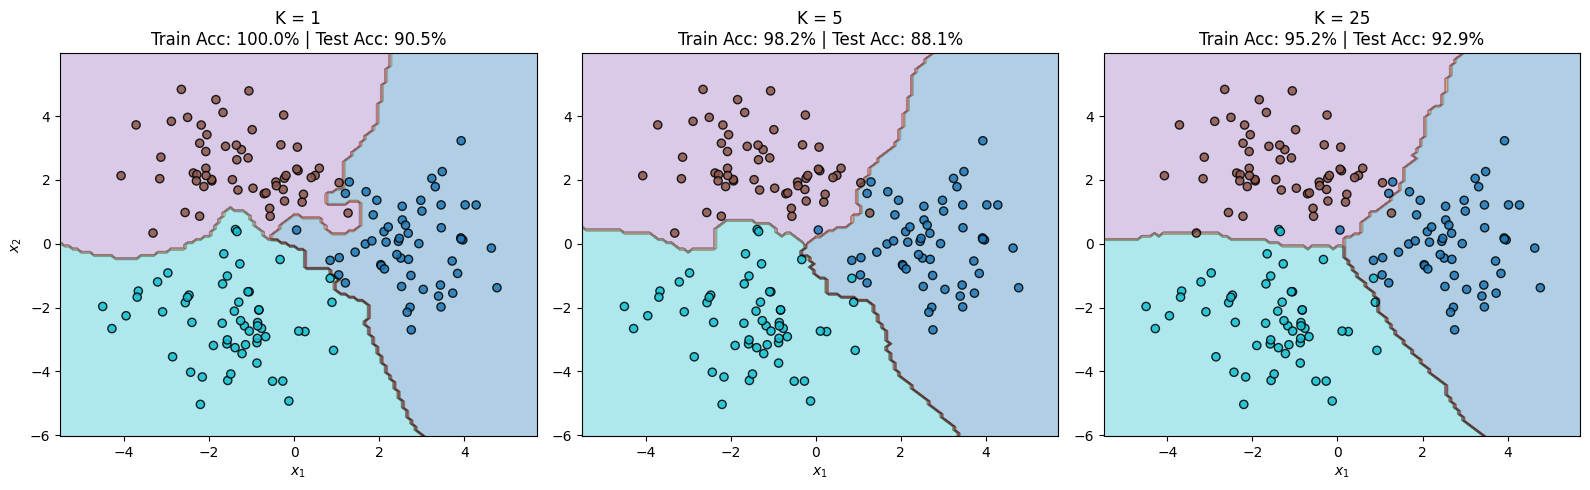

In [40]:
# Visual comparison of decision boundaries for k = 1, 5, 25
fig_k_values = [1, 5, 25]

plt.figure(figsize=(16, 5))
h = 0.1
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
grid_points = np.c_[xx.ravel(), yy.ravel()]

for idx, current_k in enumerate(fig_k_values, 1):
    clf = KNNClassifier(k=current_k, distance_func=euclidean_distance)
    clf.fit(X_train, y_train)
    Z = clf.predict(grid_points).reshape(xx.shape)
    
    plt.subplot(1, 3, idx)
    plt.contourf(xx, yy, Z, alpha=0.35, cmap='tab10')
    plt.contour(xx, yy, Z, colors='k', linewidths=0.5, alpha=0.3)
    plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='tab10', edgecolors='k', s=35, alpha=0.85)
    train_acc = accuracy_score(y_train, clf.predict(X_train))
    test_acc = accuracy_score(y_test, clf.predict(X_test))
    plt.title(f'K = {current_k}\nTrain Acc: {train_acc*100:.1f}% | Test Acc: {test_acc*100:.1f}%', fontsize=12)
    plt.xlabel('$x_1$')
    if idx == 1:
        plt.ylabel('$x_2$')

plt.tight_layout()
plt.show()

## Finding the Optimal $K$: Accuracy Curve

We evaluate training and testing accuracy across $K \in [1, 30]$ to identify the optimal value that avoids both overfitting and underfitting.

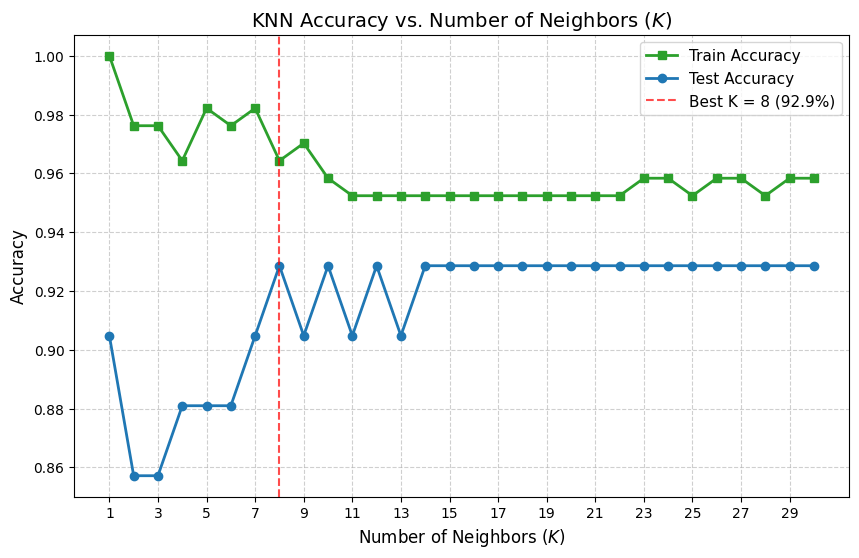

Optimal K: 8 with Test Accuracy: 92.86%


In [41]:
k_range = range(1, 31)
train_scores = []
test_scores = []

for k_val in k_range:
    model = KNNClassifier(k=k_val, distance_func=euclidean_distance)
    model.fit(X_train, y_train)
    
    train_scores.append(accuracy_score(y_train, model.predict(X_train)))
    test_scores.append(accuracy_score(y_test, model.predict(X_test)))

# Find best k based on test accuracy
best_k = list(k_range)[np.argmax(test_scores)]
best_test_acc = max(test_scores)

plt.figure(figsize=(10, 6))
plt.plot(k_range, train_scores, label='Train Accuracy', marker='s', color='#2ca02c', linewidth=2)
plt.plot(k_range, test_scores, label='Test Accuracy', marker='o', color='#1f77b4', linewidth=2)
plt.axvline(best_k, color='red', linestyle='--', alpha=0.7, label=f'Best K = {best_k} ({best_test_acc*100:.1f}%)')

plt.title('KNN Accuracy vs. Number of Neighbors ($K$)', fontsize=14)
plt.xlabel('Number of Neighbors ($K$)', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.xticks(list(k_range)[::2])
plt.legend(frameon=True, fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print(f"Optimal K: {best_k} with Test Accuracy: {best_test_acc * 100:.2f}%")

## Multivariable Example: The Critical Role of Feature Scaling

Just like in the house price prediction example in **Gradient Descent**, feature scaling is fundamentally essential for KNN, but for an even more direct reason:

Because distance is computed across coordinates:
$$d(\mathbf{x}^{(a)}, \mathbf{x}^{(b)}) = \sqrt{(x_1^{(a)} - x_1^{(b)})^2 + (x_2^{(a)} - x_2^{(b)})^2}$$

If feature $x_1$ has values in the hundreds while feature $x_2$ is between 1 and 5, the contribution of $x_2$ to the distance is completely swallowed by $x_1$.

### Example: Classifying Houses as Budget (0) vs. Luxury (1)
- $x_1$: Area ($45 - 200\text{ m}^2$)
- $x_2$: Number of Bedrooms ($1 - 5$)

We standardize features using training set statistics:
$$z_j = \frac{x_j - \mu_j}{\sigma_j}$$

In [42]:
np.random.seed(0)
n_houses = 150

# Feature 1: Area (m²) between 50 and 250
area = np.random.uniform(50, 250, size=n_houses)

# Feature 2: Bedrooms between 1 and 5
bedrooms = np.random.randint(1, 6, size=n_houses)

# Luxury condition: depends on both Area and Bedrooms equally
# Because area has a much larger numeric magnitude, scaling is critical
score = (area / 40.0) + 2.0 * bedrooms + np.random.normal(0, 0.5, size=n_houses)
y_house = (score > 9.5).astype(int)

X_house = np.column_stack([area, bedrooms])

# Split into train and test sets
X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(
    X_house, y_house, test_size=0.25, random_state=42, stratify=y_house
)

print("Sample raw training data [Area (m²), Bedrooms]:")
print(X_h_train[:4])

Sample raw training data [Area (m²), Bedrooms]:
[[110.31496333   4.        ]
 [ 64.20721164   3.        ]
 [168.17455225   1.        ]
 [132.932388     1.        ]]


### Comparing KNN Before vs. After Feature Scaling

Notice how scaling the features drastically improves KNN's test accuracy by allowing the bedroom count to influence neighbor distances fairly.

In [43]:
# 1. KNN on RAW (unscaled) features
knn_raw = KNNClassifier(k=5, distance_func=euclidean_distance)
knn_raw.fit(X_h_train, y_h_train)
acc_raw = accuracy_score(y_h_test, knn_raw.predict(X_h_test))

# 2. Compute mean and standard deviation from training data only
X_mean = X_h_train.mean(axis=0)
X_std = X_h_train.std(axis=0)

# Standardize train and test features
X_h_train_scaled = (X_h_train - X_mean) / X_std
X_h_test_scaled = (X_h_test - X_mean) / X_std

# 3. KNN on SCALED features (labels y_h_train are unchanged)
knn_scaled = KNNClassifier(k=5, distance_func=euclidean_distance)
knn_scaled.fit(X_h_train_scaled, y_h_train)
acc_scaled = accuracy_score(y_h_test, knn_scaled.predict(X_h_test_scaled))

print(f"Accuracy WITHOUT Feature Scaling: {acc_raw * 100:.2f}%")
print(f"Accuracy WITH Feature Scaling:    {acc_scaled * 100:.2f}%")
print(f"Accuracy Improvement:            +{(acc_scaled - acc_raw) * 100:.2f}%")

Accuracy WITHOUT Feature Scaling: 65.79%
Accuracy WITH Feature Scaling:    92.11%
Accuracy Improvement:            +26.32%


### Make a Prediction for a New House

Suppose we want to classify a new listing:
- **Area:** $130\text{ m}^2$
- **Bedrooms:** $4$

Before prediction, we standardize its features with **the exact mean and standard deviation of the training data**.

In [44]:
# New observation: [160 m², 4 bedrooms]
new_house = np.array([[160.0, 4.0]])

# Standardize using training parameters
new_house_scaled = (new_house - X_mean) / X_std

# Predict label
prediction = knn_scaled.predict(new_house_scaled)[0]
label_names = {0: 'Budget Property', 1: 'Luxury Property'}

print(f"New House: Area = {new_house[0,0]} m², Bedrooms = {int(new_house[0,1])}")
print(f"Standardized Features: [Area_z = {new_house_scaled[0,0]:.2f}, Bedrooms_z = {new_house_scaled[0,1]:.2f}]")
print(f"Predicted Class: {prediction} ({label_names[prediction]})")

# Find and display its 5 nearest neighbors in the training set
distances_to_new = np.array([euclidean_distance(new_house_scaled[0], xt) for xt in X_h_train_scaled])
k_nearest_indices = np.argsort(distances_to_new)[:5]

print("\n5 Nearest Neighbors in Training Set:")
for idx in k_nearest_indices:
    orig_area, orig_bed = X_h_train[idx]
    orig_label = label_names[y_h_train[idx]]
    dist = distances_to_new[idx]
    print(f" - Neighbor: Area = {orig_area:.1f} m², Beds = {int(orig_bed)} | Class = {orig_label} | Distance = {dist:.3f}")

New House: Area = 160.0 m², Bedrooms = 4
Standardized Features: [Area_z = 0.13, Bedrooms_z = 0.67]
Predicted Class: 1 (Luxury Property)

5 Nearest Neighbors in Training Set:
 - Neighbor: Area = 159.0 m², Beds = 4 | Class = Luxury Property | Distance = 0.019
 - Neighbor: Area = 165.2 m², Beds = 4 | Class = Luxury Property | Distance = 0.095
 - Neighbor: Area = 150.3 m², Beds = 4 | Class = Luxury Property | Distance = 0.178
 - Neighbor: Area = 173.4 m², Beds = 4 | Class = Luxury Property | Distance = 0.245
 - Neighbor: Area = 143.7 m², Beds = 4 | Class = Luxury Property | Distance = 0.297


## Verification with Scikit-Learn

We verify our from-scratch implementation against `KNeighborsClassifier` from `sklearn.neighbors`.

In [45]:
from sklearn.neighbors import KNeighborsClassifier

# Train Scikit-Learn's KNN on scaled data
sklearn_knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
sklearn_knn.fit(X_h_train_scaled, y_h_train)

sklearn_pred = sklearn_knn.predict(X_h_test_scaled)
scratch_pred = knn_scaled.predict(X_h_test_scaled)

# Compare predictions
matching = np.sum(sklearn_pred == scratch_pred)
total = len(y_h_test)

print(f"Scikit-Learn Accuracy: {accuracy_score(y_h_test, sklearn_pred) * 100:.2f}%")
print(f"From-Scratch Accuracy: {accuracy_score(y_h_test, scratch_pred) * 100:.2f}%")
print(f"Predictions Match:     {matching}/{total} ({matching/total*100:.1f}%)")

Scikit-Learn Accuracy: 92.11%
From-Scratch Accuracy: 92.11%
Predictions Match:     38/38 (100.0%)


## Summary and Key Takeaways

| Concept / Aspect | K-Nearest Neighbors (KNN) |
| :--- | :--- |
| **Model Nature** | Non-parametric, Instance-based (Lazy Learner) |
| **Training Complexity** | $\mathcal{O}(1)$ — just stores the dataset |
| **Prediction Complexity** | $\mathcal{O}(m \cdot d)$ per query — expensive for large datasets ($m$) or high dimensions ($d$) |
| **Memory Complexity** | $\mathcal{O}(m \cdot d)$ — keeps entire training set in memory |
| **Hyperparameter $K$** | Small $K \implies$ Overfitting (High Variance); Large $K \implies$ Underfitting (High Bias) |
| **Distance Metrics** | Euclidean ($L_2$), Manhattan ($L_1$), Minkowski ($L_p$) |
| **Preprocessing Requirement** | **Feature Scaling is mandatory** (otherwise large-scale features dominate distance) |
| **Curse of Dimensionality** | In high dimensions, points become equidistant; dimensionality reduction (PCA) is often needed |